In [1]:
#EXPLORATORY DATA ANALYSIS
#COURSE PROJECT
#DATASET: https://raw.githubusercontent.com/salemprakash/EDA/main/Data/Fishing.csv
#NAME:PRASANNA SHRUTHI S
#REG.NO:23BDS0301


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import silhouette_score

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

In [3]:
#LOAD DATASET
url = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/Fishing.csv"

data = pd.read_csv(url)

print("First 5 records:")
display(data.head())

print("Dataset shape:", data.shape)
print("Column names:", data.columns.tolist())

First 5 records:


,rownames,mode,price,catch,pbeach,ppier,pboat,pcharter,cbeach,cpier,cboat,ccharter,income
0,1,charter,182.930,0.5391,157.930,157.930,157.930,182.930,0.0678,0.0503,0.2601,0.5391,7083.3317
1,2,charter,34.534,0.4671,15.114,15.114,10.534,34.534,0.1049,0.0451,0.1574,0.4671,1249.9998
2,3,boat,24.334,0.2413,161.874,161.874,24.334,59.334,0.5333,0.4522,0.2413,1.0266,3749.9999
3,4,pier,15.134,0.0789,15.134,15.134,55.930,84.930,0.0678,0.0789,0.1643,0.5391,2083.3332
4,5,boat,41.514,0.1082,106.930,106.930,41.514,71.014,0.0678,0.0503,0.1082,0.3240,4583.3320


Dataset shape: (1182, 13)
Column names: ['rownames', 'mode', 'price', 'catch', 'pbeach', 'ppier', 'pboat', 'pcharter', 'cbeach', 'cpier', 'cboat', 'ccharter', 'income']


In [4]:
print("First 10 records:")
display(data.head(10))

print("Last 10 records:")
display(data.tail(10))

print("Rows:", data.shape[0])
print("Columns:", data.shape[1])

print("Data types:")
print(data.dtypes)

print("Summary statistics:")
display(data.describe(include="all"))

First 10 records:


,rownames,mode,price,catch,pbeach,ppier,pboat,pcharter,cbeach,cpier,cboat,ccharter,income
0,1,charter,182.930,0.5391,157.930,157.930,157.930,182.930,0.0678,0.0503,0.2601,0.5391,7083.3317
1,2,charter,34.534,0.4671,15.114,15.114,10.534,34.534,0.1049,0.0451,0.1574,0.4671,1249.9998
2,3,boat,24.334,0.2413,161.874,161.874,24.334,59.334,0.5333,0.4522,0.2413,1.0266,3749.9999
3,4,pier,15.134,0.0789,15.134,15.134,55.930,84.930,0.0678,0.0789,0.1643,0.5391,2083.3332
4,5,boat,41.514,0.1082,106.930,106.930,41.514,71.014,0.0678,0.0503,0.1082,0.3240,4583.3320
5,6,charter,63.934,0.3975,192.474,192.474,28.934,63.934,0.5333,0.4522,0.1665,0.3975,4583.3320
6,7,beach,51.934,0.0678,51.934,51.934,191.930,220.930,0.0678,0.0789,0.1643,0.5391,8750.0010
7,8,charter,56.714,0.0209,15.134,15.134,21.714,56.714,0.0678,0.0789,0.0102,0.0209,2083.3332
8,9,boat,34.914,0.0233,34.914,34.914,34.914,53.414,0.2537,0.1498,0.0233,0.0219,3749.9999
9,10,boat,28.314,0.0233,28.314,28.314,28.314,46.814,0.2537,0.1498,0.0233,0.0219,2916.6666


Last 10 records:


,rownames,mode,price,catch,pbeach,ppier,pboat,pcharter,cbeach,cpier,cboat,ccharter,income
1172,1173,charter,63.902,0.0219,45.402,45.402,45.402,63.902,0.2537,0.1498,0.0233,0.0219,2083.33320
1173,1174,beach,62.634,0.0678,62.634,62.634,123.552,152.552,0.0678,0.0789,0.0014,0.0029,2916.66660
1174,1175,boat,86.802,0.0102,91.834,91.834,86.802,121.802,0.0678,0.0789,0.0102,0.0209,4583.33200
1175,1176,charter,149.402,0.0209,121.034,121.034,114.402,149.402,0.0678,0.0789,0.0102,0.0209,6250.00130
1176,1177,beach,121.836,0.5333,121.836,121.836,203.346,238.346,0.5333,0.4522,0.2413,1.0266,2916.66660
1177,1178,pier,150.236,0.4522,150.236,150.236,250.746,285.746,0.5333,0.4522,0.2413,1.0266,3749.99990
1178,1179,beach,235.436,0.5333,235.436,235.436,392.946,427.946,0.5333,0.4522,0.2413,1.0266,6250.00130
1179,1180,pier,65.036,0.4522,65.036,65.036,108.546,143.546,0.5333,0.4522,0.2413,1.0266,1249.99980
1180,1181,beach,36.636,0.5333,36.636,36.636,61.146,96.146,0.5333,0.4522,0.1665,0.3975,416.66668
1181,1182,boat,235.436,0.6817,339.890,339.890,235.436,260.436,0.2537,0.1498,0.6817,2.3014,6250.00130


Rows: 1182
Columns: 13
Data types:
rownames      int64
mode         object
price       float64
catch       float64
pbeach      float64
ppier       float64
pboat       float64
pcharter    float64
cbeach      float64
cpier       float64
cboat       float64
ccharter    float64
income      float64
dtype: object
Summary statistics:


,rownames,mode,price,catch,pbeach,ppier,pboat,pcharter,cbeach,cpier,cboat,ccharter,income
count,1182.000000,1182,1182.000000,1182.000000,1182.000000,1182.000000,1182.000000,1182.000000,1182.000000,1182.000000,1182.000000,1182.000000,1182.000000
unique,NaN,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,charter,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,452,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,591.500000,NaN,52.081975,0.389368,103.422005,103.422005,55.256570,84.379244,0.241011,0.162224,0.171215,0.629368,4099.337054
std,341.358316,NaN,53.829970,0.560596,103.641042,103.641042,62.713444,63.544650,0.190752,0.160390,0.209789,0.706114,2461.964060
min,1.000000,NaN,1.290000,0.000200,1.290000,1.290000,2.290000,27.290000,0.067800,0.001400,0.000200,0.002100,416.666680
25%,296.250000,NaN,15.870000,0.036100,26.656500,26.656500,13.122000,42.896000,0.067800,0.050300,0.023300,0.021900,2083.333200
50%,591.500000,NaN,37.896000,0.164300,74.628000,74.628000,33.534000,61.607000,0.253700,0.078900,0.089700,0.421600,3749.999900
75%,886.750000,NaN,67.513000,0.533300,144.144000,144.144000,72.402000,102.774000,0.533300,0.149800,0.241300,1.026600,5416.666700


In [5]:
#DATAFRAME OPERATIONS
dataframe1 = pd.DataFrame({
    "ProductID": range(101, 111),
    "NameofProd": [
        "Laptop", "Mouse", "Keyboard", "Monitor", "Printer",
        "Speaker", "Tablet", "Camera", "Headphone", "Charger"
    ],
    "Price": [55000, 800, 1500, 12000, 9000, 2500, 22000, 35000, 1800, 900]
})

dataframe2 = pd.DataFrame({
    "ProductID": range(101, 111),
    "Company_Location": [
        "Delhi", "Mumbai", "Bangalore", "Chennai", "Hyderabad",
        "Pune", "Kolkata", "Jaipur", "Lucknow", "Ahmedabad"
    ]
})

dataframe3 = pd.DataFrame({
    "ProductID": range(111, 121),
    "NameofProd": [
        "SmartWatch", "SSD", "RAM", "Router", "Projector",
        "Pendrive", "Microphone", "PowerBank", "Scanner", "Webcam"
    ],
    "Price": [5000, 4500, 3200, 2800, 30000, 900, 4000, 1500, 8000, 2500]
})

print("Append:")
display(pd.concat([dataframe1, dataframe3], ignore_index=True))

print("Concatenate columns:")
display(pd.concat([dataframe1, dataframe2[["Company_Location"]]], axis=1))

print("Merge:")
display(pd.merge(dataframe1, dataframe2, on="ProductID"))

for join_type in ["inner", "left", "right", "outer"]:
    print(join_type.upper(), "JOIN")
    display(pd.merge(dataframe1, dataframe2, on="ProductID", how=join_type))

Append:


,ProductID,NameofProd,Price
0,101,Laptop,55000
1,102,Mouse,800
2,103,Keyboard,1500
3,104,Monitor,12000
4,105,Printer,9000
5,106,Speaker,2500
6,107,Tablet,22000
7,108,Camera,35000
8,109,Headphone,1800
9,110,Charger,900


Concatenate columns:


,ProductID,NameofProd,Price,Company_Location
0,101,Laptop,55000,Delhi
1,102,Mouse,800,Mumbai
2,103,Keyboard,1500,Bangalore
3,104,Monitor,12000,Chennai
4,105,Printer,9000,Hyderabad
5,106,Speaker,2500,Pune
6,107,Tablet,22000,Kolkata
7,108,Camera,35000,Jaipur
8,109,Headphone,1800,Lucknow
9,110,Charger,900,Ahmedabad


Merge:


,ProductID,NameofProd,Price,Company_Location
0,101,Laptop,55000,Delhi
1,102,Mouse,800,Mumbai
2,103,Keyboard,1500,Bangalore
3,104,Monitor,12000,Chennai
4,105,Printer,9000,Hyderabad
5,106,Speaker,2500,Pune
6,107,Tablet,22000,Kolkata
7,108,Camera,35000,Jaipur
8,109,Headphone,1800,Lucknow
9,110,Charger,900,Ahmedabad


... (4 outputs left out)

RIGHT JOIN


,ProductID,NameofProd,Price,Company_Location
0,101,Laptop,55000,Delhi
1,102,Mouse,800,Mumbai
2,103,Keyboard,1500,Bangalore
3,104,Monitor,12000,Chennai
4,105,Printer,9000,Hyderabad
5,106,Speaker,2500,Pune
6,107,Tablet,22000,Kolkata
7,108,Camera,35000,Jaipur
8,109,Headphone,1800,Lucknow
9,110,Charger,900,Ahmedabad


OUTER JOIN


,ProductID,NameofProd,Price,Company_Location
0,101,Laptop,55000,Delhi
1,102,Mouse,800,Mumbai
2,103,Keyboard,1500,Bangalore
3,104,Monitor,12000,Chennai
4,105,Printer,9000,Hyderabad
5,106,Speaker,2500,Pune
6,107,Tablet,22000,Kolkata
7,108,Camera,35000,Jaipur
8,109,Headphone,1800,Lucknow
9,110,Charger,900,Ahmedabad


In [6]:
#MISSING VALUES ANALYSIS
print("Missing values in each column:")
print(data.isnull().sum())

print("Total missing values:")
print(data.isnull().sum().sum())

print("Rows containing missing values:")
display(data[data.isnull().any(axis=1)])

clean_data = data.dropna()

print("Dataset after removing missing values:")
display(clean_data.head())

Missing values in each column:
rownames    0
mode        0
price       0
catch       0
pbeach      0
ppier       0
pboat       0
pcharter    0
cbeach      0
cpier       0
cboat       0
ccharter    0
income      0
dtype: int64
Total missing values:
0
Rows containing missing values:


,rownames,mode,price,catch,pbeach,ppier,pboat,pcharter,cbeach,cpier,cboat,ccharter,income


Dataset after removing missing values:


,rownames,mode,price,catch,pbeach,ppier,pboat,pcharter,cbeach,cpier,cboat,ccharter,income
0,1,charter,182.930,0.5391,157.930,157.930,157.930,182.930,0.0678,0.0503,0.2601,0.5391,7083.3317
1,2,charter,34.534,0.4671,15.114,15.114,10.534,34.534,0.1049,0.0451,0.1574,0.4671,1249.9998
2,3,boat,24.334,0.2413,161.874,161.874,24.334,59.334,0.5333,0.4522,0.2413,1.0266,3749.9999
3,4,pier,15.134,0.0789,15.134,15.134,55.930,84.930,0.0678,0.0789,0.1643,0.5391,2083.3332
4,5,boat,41.514,0.1082,106.930,106.930,41.514,71.014,0.0678,0.0503,0.1082,0.3240,4583.3320


In [7]:
fishing_demo = data.copy()

# Create a few missing values to demonstrate cleaning
fishing_demo.loc[1, "price"] = np.nan
fishing_demo.loc[4, "income"] = np.nan
fishing_demo.loc[7, "mode"] = np.nan

missing_percentage = fishing_demo.isnull().mean() * 100

fishing_demo = fishing_demo.loc[
    :, missing_percentage <= 70
].copy()

print("Missing percentage:")
print(missing_percentage)

mean_data = fishing_demo.copy()
median_data = fishing_demo.copy()
mode_data = fishing_demo.copy()

numeric_cols = fishing_demo.select_dtypes(include=np.number).columns
categorical_cols = fishing_demo.select_dtypes(exclude=np.number).columns

for col in numeric_cols:
    mean_data[col] = mean_data[col].fillna(mean_data[col].mean())
    median_data[col] = median_data[col].fillna(median_data[col].median())

for col in categorical_cols:
    if not mode_data[col].mode().empty:
        mode_data[col] = mode_data[col].fillna(mode_data[col].mode()[0])

print("Mean imputation:")
display(mean_data.head())

print("Median imputation:")
display(median_data.head())

print("Mode imputation:")
display(mode_data.head())

Missing percentage:
rownames    0.000000
mode        0.084602
price       0.084602
catch       0.000000
pbeach      0.000000
ppier       0.000000
pboat       0.000000
pcharter    0.000000
cbeach      0.000000
cpier       0.000000
cboat       0.000000
ccharter    0.000000
income      0.084602
dtype: float64
Mean imputation:


,rownames,mode,price,catch,pbeach,ppier,pboat,pcharter,cbeach,cpier,cboat,ccharter,income
0,1,charter,182.930000,0.5391,157.930,157.930,157.930,182.930,0.0678,0.0503,0.2601,0.5391,7083.331700
1,2,charter,52.096833,0.4671,15.114,15.114,10.534,34.534,0.1049,0.0451,0.1574,0.4671,1249.999800
2,3,boat,24.334000,0.2413,161.874,161.874,24.334,59.334,0.5333,0.4522,0.2413,1.0266,3749.999900
3,4,pier,15.134000,0.0789,15.134,15.134,55.930,84.930,0.0678,0.0789,0.1643,0.5391,2083.333200
4,5,boat,41.514000,0.1082,106.930,106.930,41.514,71.014,0.0678,0.0503,0.1082,0.3240,4098.927236


Median imputation:


,rownames,mode,price,catch,pbeach,ppier,pboat,pcharter,cbeach,cpier,cboat,ccharter,income
0,1,charter,182.930,0.5391,157.930,157.930,157.930,182.930,0.0678,0.0503,0.2601,0.5391,7083.3317
1,2,charter,37.896,0.4671,15.114,15.114,10.534,34.534,0.1049,0.0451,0.1574,0.4671,1249.9998
2,3,boat,24.334,0.2413,161.874,161.874,24.334,59.334,0.5333,0.4522,0.2413,1.0266,3749.9999
3,4,pier,15.134,0.0789,15.134,15.134,55.930,84.930,0.0678,0.0789,0.1643,0.5391,2083.3332
4,5,boat,41.514,0.1082,106.930,106.930,41.514,71.014,0.0678,0.0503,0.1082,0.3240,3749.9999


Mode imputation:


,rownames,mode,price,catch,pbeach,ppier,pboat,pcharter,cbeach,cpier,cboat,ccharter,income
0,1,charter,182.930,0.5391,157.930,157.930,157.930,182.930,0.0678,0.0503,0.2601,0.5391,7083.3317
1,2,charter,NaN,0.4671,15.114,15.114,10.534,34.534,0.1049,0.0451,0.1574,0.4671,1249.9998
2,3,boat,24.334,0.2413,161.874,161.874,24.334,59.334,0.5333,0.4522,0.2413,1.0266,3749.9999
3,4,pier,15.134,0.0789,15.134,15.134,55.930,84.930,0.0678,0.0789,0.1643,0.5391,2083.3332
4,5,boat,41.514,0.1082,106.930,106.930,41.514,71.014,0.0678,0.0503,0.1082,0.3240,NaN


In [8]:
#DATA NORMALIZATION

PrasannaShruthi = np.array(
    [301, 95, 100, 111, 120, 125, 130, 145, 160, 170],
    dtype=float
)

def normalize(x, low, high):
    return ((x - x.min()) / (x.max() - x.min())) * (high - low) + low

print("Original:", PrasannaShruthi)
print("[-3, 3]:", normalize(PrasannaShruthi, -3, 3))
print("[-1, 1]:", normalize(PrasannaShruthi, -1, 1))
print("[0, 1]:", normalize(PrasannaShruthi, 0, 1))

z_score = stats.zscore(PrasannaShruthi, ddof=1)
print("Z-score:", z_score)

j = len(str(int(np.max(np.abs(PrasannaShruthi)))))
decimal_scaling = PrasannaShruthi / (10 ** j)

print("Decimal scaling:", decimal_scaling)

Original: [301.  95. 100. 111. 120. 125. 130. 145. 160. 170.]
[-3, 3]: [ 3.         -3.         -2.85436893 -2.53398058 -2.27184466 -2.12621359
 -1.98058252 -1.54368932 -1.10679612 -0.81553398]
[-1, 1]: [ 1.         -1.         -0.95145631 -0.84466019 -0.75728155 -0.70873786
 -0.66019417 -0.51456311 -0.36893204 -0.27184466]
[0, 1]: [1.         0.         0.02427184 0.0776699  0.12135922 0.14563107
 0.16990291 0.24271845 0.31553398 0.36407767]
Z-score: [ 2.59991025 -0.84877946 -0.7650734  -0.58092006 -0.43024915 -0.34654309
 -0.26283703 -0.01171885  0.23939933  0.40681146]
Decimal scaling: [0.301 0.095 0.1   0.111 0.12  0.125 0.13  0.145 0.16  0.17 ]


In [9]:
#STATISTICAL ANALYSIS

numeric_data = data.select_dtypes(include=np.number)

summary = pd.DataFrame({
    "Mean": numeric_data.mean(),
    "Median": numeric_data.median(),
    "Minimum": numeric_data.min(),
    "Maximum": numeric_data.max(),
    "Range": numeric_data.max() - numeric_data.min(),
    "Variance": numeric_data.var(),
    "Standard Deviation": numeric_data.std(),
    "IQR": numeric_data.quantile(0.75) - numeric_data.quantile(0.25),
    "Skewness": numeric_data.skew(),
    "Kurtosis": numeric_data.kurt()
})

display(summary.round(3))

,Mean,Median,Minimum,Maximum,Range,Variance,Standard Deviation,IQR,Skewness,Kurtosis
rownames,591.500,591.500,1.000,1182.000,1181.000,116525.500,341.358,590.500,0.000,-1.200
price,52.082,37.896,1.290,666.110,664.820,2897.666,53.830,51.643,3.147,19.309
catch,0.389,0.164,0.000,2.310,2.310,0.314,0.561,0.497,2.352,5.272
pbeach,103.422,74.628,1.290,843.186,841.896,10741.466,103.641,117.488,1.875,5.008
ppier,103.422,74.628,1.290,843.186,841.896,10741.466,103.641,117.488,1.875,5.008
pboat,55.257,33.534,2.290,666.110,663.820,3932.976,62.713,59.280,2.657,12.346
pcharter,84.379,61.607,27.290,691.110,663.820,4037.922,63.545,59.878,2.598,11.716
cbeach,0.241,0.254,0.068,0.533,0.466,0.036,0.191,0.466,0.632,-1.236
cpier,0.162,0.079,0.001,0.452,0.451,0.026,0.160,0.099,1.075,-0.465
cboat,0.171,0.090,0.000,0.737,0.737,0.044,0.210,0.218,1.674,1.752


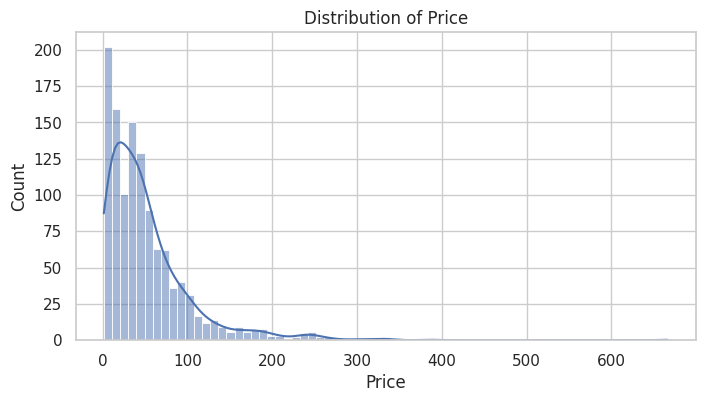

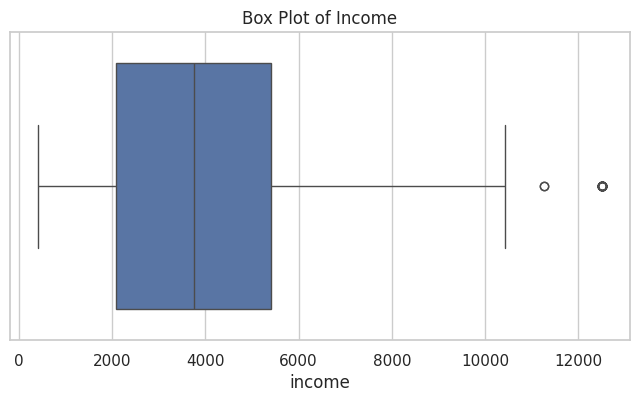

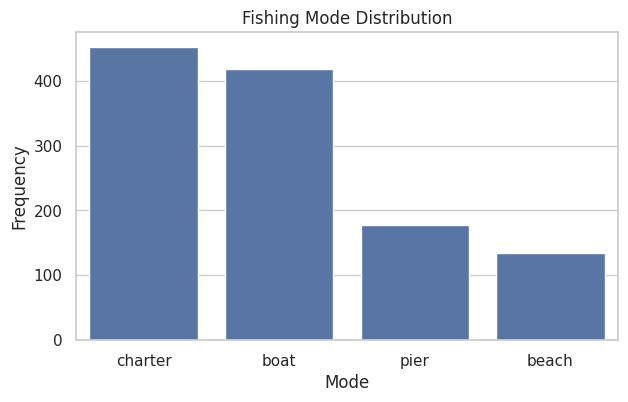

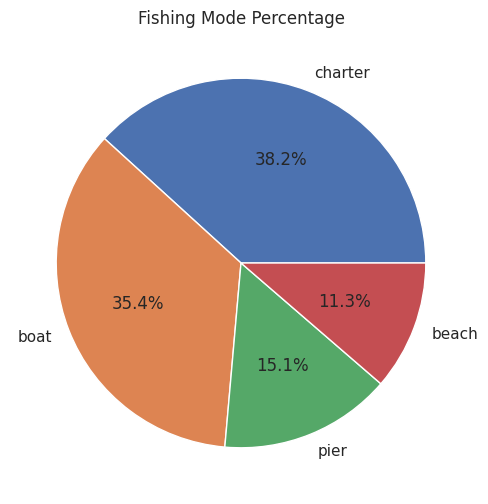

In [10]:
#UNIVARIATE

plt.figure(figsize=(8, 4))
sns.histplot(data["price"].dropna(), kde=True)
plt.title("Distribution of Price")
plt.xlabel("Price")
plt.show()

plt.figure(figsize=(8, 4))
sns.boxplot(x=data["income"])
plt.title("Box Plot of Income")
plt.show()

mode_counts = data["mode"].value_counts()

plt.figure(figsize=(7, 4))
sns.barplot(x=mode_counts.index, y=mode_counts.values)
plt.title("Fishing Mode Distribution")
plt.xlabel("Mode")
plt.ylabel("Frequency")
plt.show()

plt.figure(figsize=(6, 6))
plt.pie(mode_counts.values, labels=mode_counts.index, autopct="%1.1f%%")
plt.title("Fishing Mode Percentage")
plt.show()

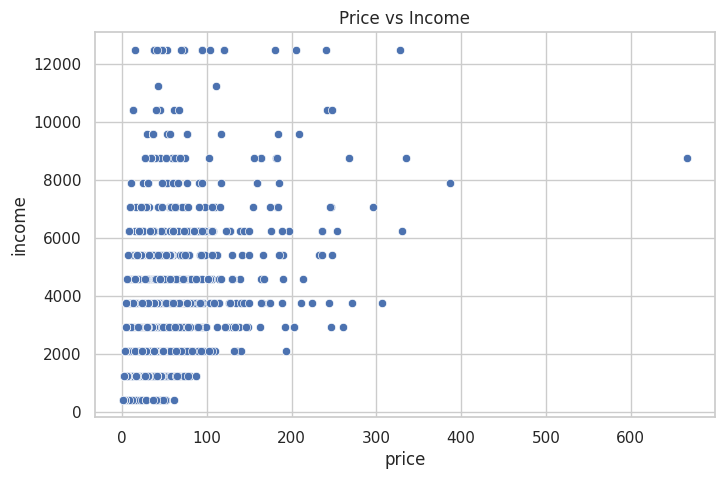

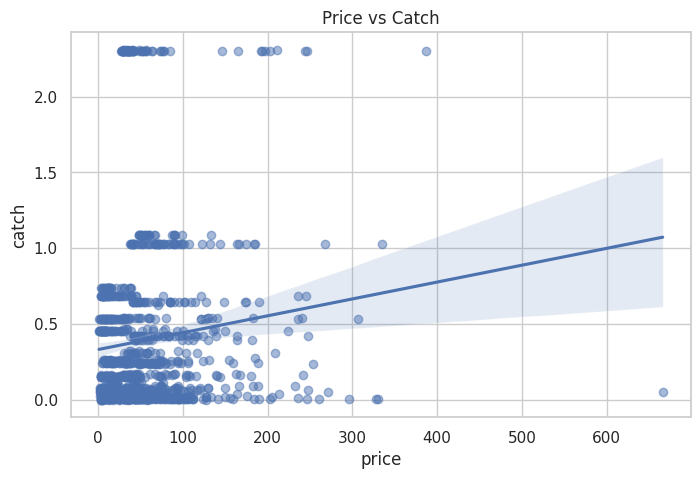

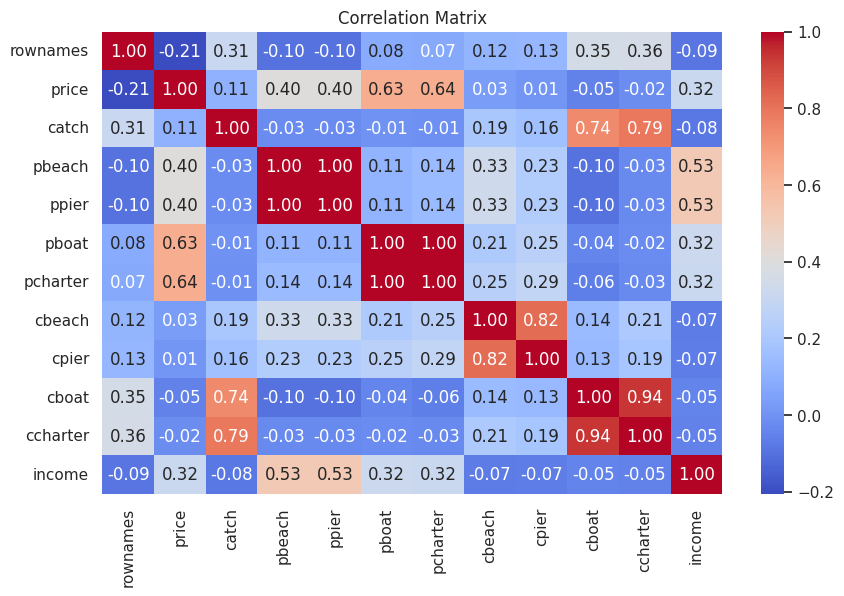

In [11]:
# BIVARIATE

plt.figure(figsize=(8, 5))
sns.scatterplot(data=data, x="price", y="income")
plt.title("Price vs Income")
plt.show()

plt.figure(figsize=(8, 5))
sns.regplot(data=data, x="price", y="catch",
            scatter_kws={"alpha": 0.5})
plt.title("Price vs Catch")
plt.show()

correlation = numeric_data.corr()

plt.figure(figsize=(10, 6))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

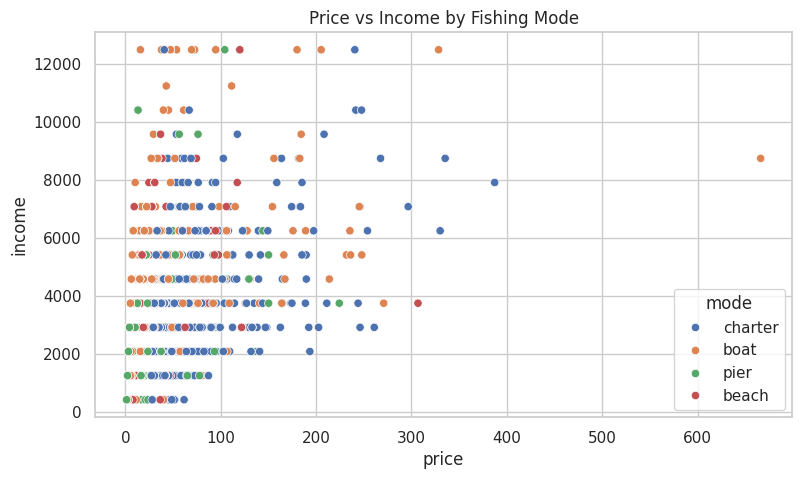

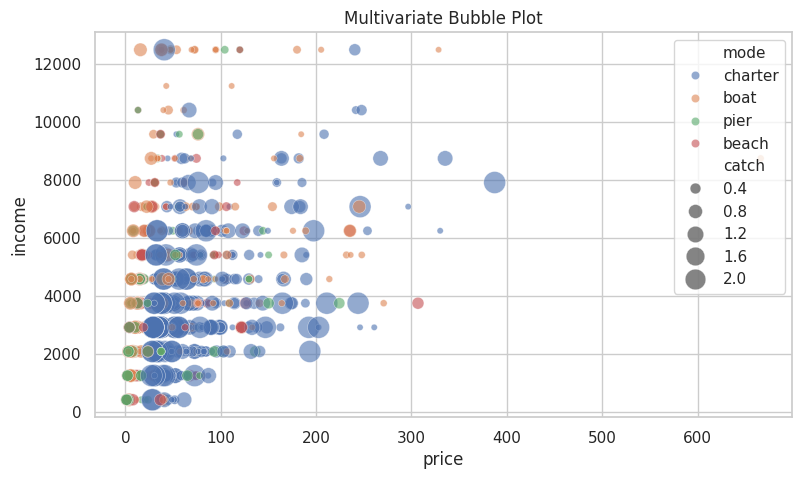

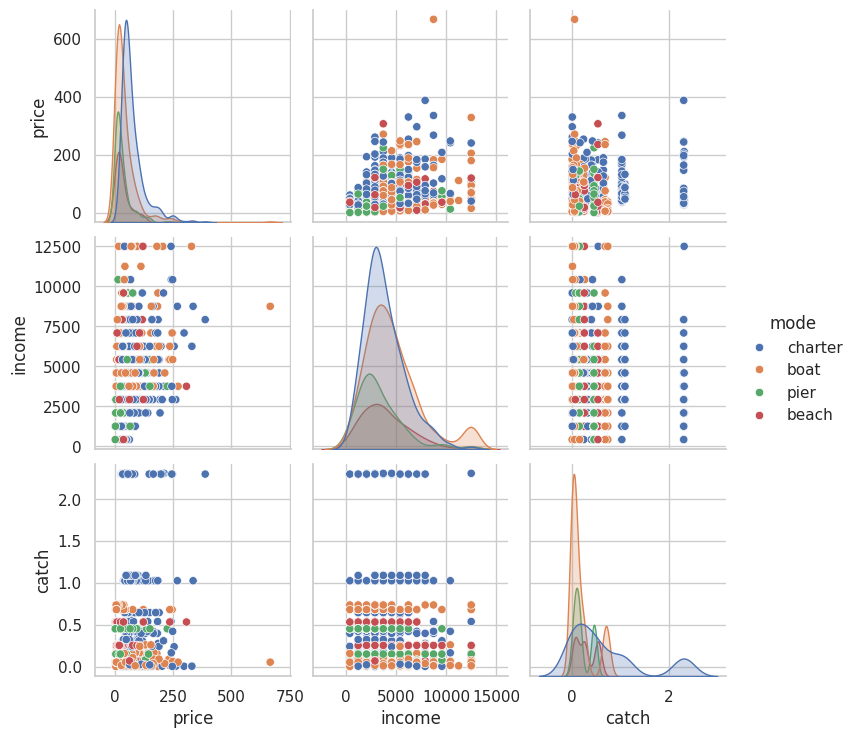

In [12]:
#MULIVARIATE ANALYSIS
plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=data,
    x="price",
    y="income",
    hue="mode"
)
plt.title("Price vs Income by Fishing Mode")
plt.show()

plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=data,
    x="price",
    y="income",
    hue="mode",
    size="catch",
    sizes=(20, 250),
    alpha=0.6
)
plt.title("Multivariate Bubble Plot")
plt.show()

sns.pairplot(data[["price", "income", "catch", "mode"]], hue="mode")
plt.show()


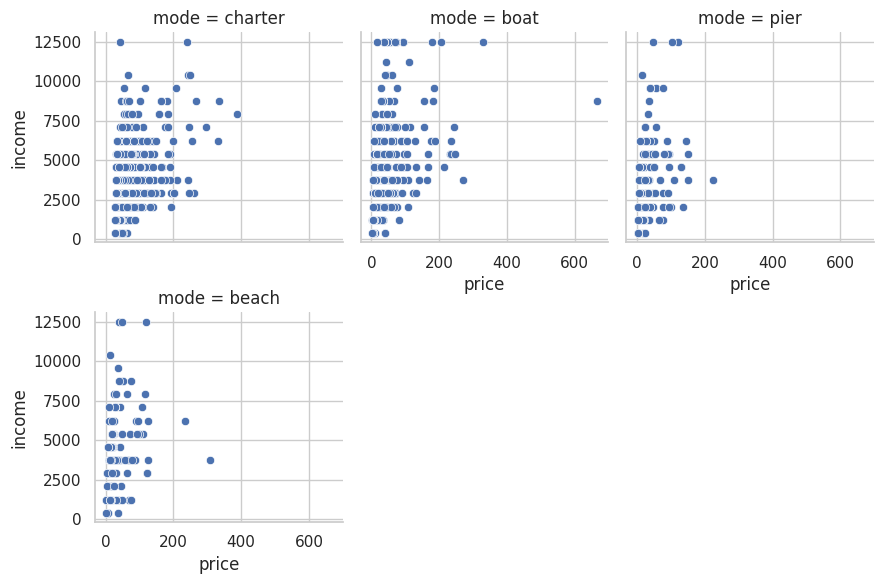

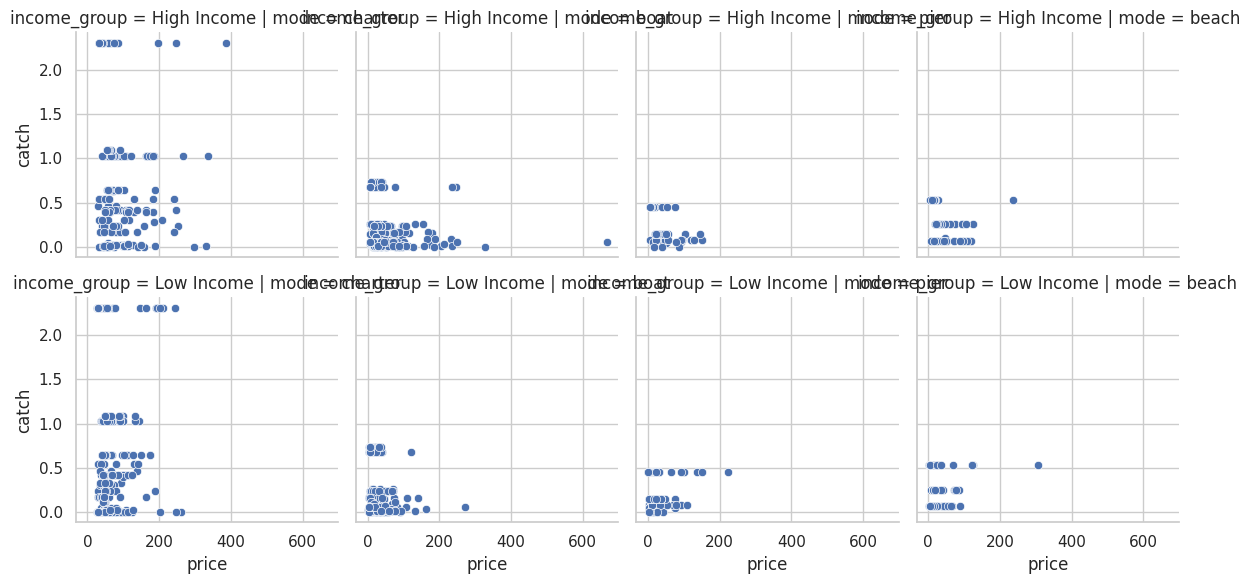

In [13]:
#FACET
sns.relplot(
    data=data,
    x="price",
    y="income",
    col="mode",
    kind="scatter",
    col_wrap=3,
    height=3
)

plt.show()

facet_data = data.copy()

facet_data["income_group"] = np.where(
    facet_data["income"] > facet_data["income"].median(),
    "High Income",
    "Low Income"
)

sns.relplot(
    data=facet_data,
    x="price",
    y="catch",
    row="income_group",
    col="mode",
    kind="scatter",
    height=3
)

plt.show()

Duplicate rows: 0
Missing values:
rownames    0
mode        0
price       0
catch       0
pbeach      0
ppier       0
pboat       0
pcharter    0
cbeach      0
cpier       0
cboat       0
ccharter    0
income      0
dtype: int64
Number of price outliers: 67


,rownames,mode,price,catch,pbeach,ppier,pboat,pcharter,cbeach,cpier,cboat,ccharter,income
0,1,charter,182.930,0.5391,157.930,157.930,157.930,182.930,0.0678,0.0503,0.2601,0.5391,7083.3317
43,44,charter,211.208,2.3101,59.248,59.248,186.208,211.208,0.2537,0.1498,0.7369,2.3101,3749.9999
105,106,charter,181.770,0.3975,268.702,268.702,146.770,181.770,0.5333,0.4522,0.1665,0.3975,8750.0010
106,107,charter,246.102,2.3014,55.740,55.740,221.102,246.102,0.2537,0.1498,0.6817,2.3014,7083.3317
119,120,charter,296.552,0.0041,135.634,135.634,267.552,296.552,0.0678,0.0789,0.1643,0.0041,7083.3317


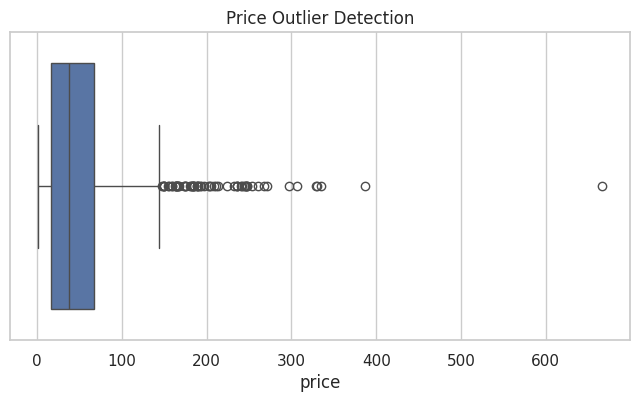

In [14]:
#DATA CLEANING AND OUTLIER DETECTION

print("Duplicate rows:", data.duplicated().sum())

data_cleaned = data.drop_duplicates().copy()

print("Missing values:")
print(data_cleaned.isnull().sum())

Q1 = data_cleaned["price"].quantile(0.25)
Q3 = data_cleaned["price"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = data_cleaned[
    (data_cleaned["price"] < lower) |
    (data_cleaned["price"] > upper)
]

print("Number of price outliers:", len(outliers))
display(outliers.head())

plt.figure(figsize=(8, 4))
sns.boxplot(x=data_cleaned["price"])
plt.title("Price Outlier Detection")
plt.show()

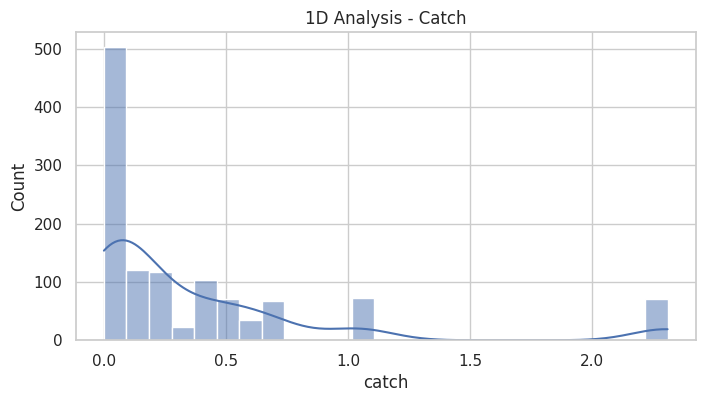

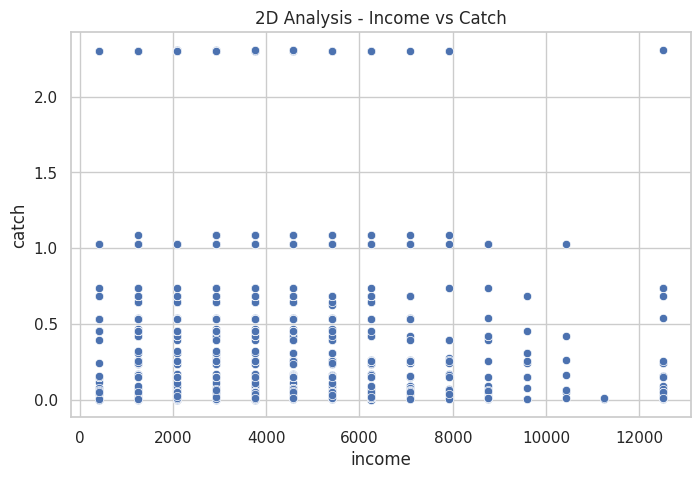

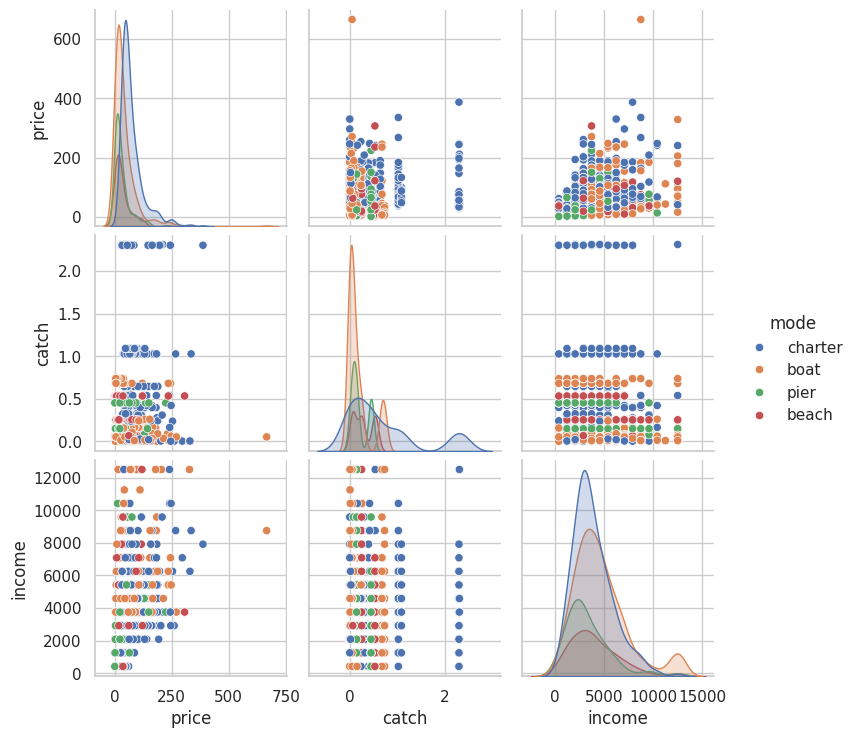

Contingency Table:
income   (404.583, 4444.444]  (4444.444, 8472.221]  (8472.221, 12499.998]
mode                                                                     
beach                     84                    42                      8
boat                     214                   162                     42
charter                  288                   146                     18
pier                     128                    41                      9


In [15]:
#1D,2D,ND ANALYSIS

# 1D Analysis
plt.figure(figsize=(8, 4))
sns.histplot(data["catch"], kde=True)
plt.title("1D Analysis - Catch")
plt.show()

# 2D Analysis
plt.figure(figsize=(8, 5))
sns.scatterplot(data=data, x="income", y="catch")
plt.title("2D Analysis - Income vs Catch")
plt.show()

# N-D Analysis
sns.pairplot(
    data[["price", "catch", "income", "mode"]],
    hue="mode"
)
plt.show()

# Contingency table
print("Contingency Table:")
print(pd.crosstab(
    data["mode"],
    pd.cut(data["income"], bins=3)
))

First 5 observations:
1949-01-01    112
1949-02-01    118
1949-03-01    132
1949-04-01    129
1949-05-01    121
Freq: MS, Name: Passengers, dtype: int64
Last 5 observations:
1960-08-01    606
1960-09-01    508
1960-10-01    461
1960-11-01    390
1960-12-01    432
Freq: MS, Name: Passengers, dtype: int64
Start: 1949-01-01 00:00:00
End: 1960-12-01 00:00:00
Frequency: Monthly
count    144.000000
mean     280.298611
std      119.966317
min      104.000000
25%      180.000000
50%      265.500000
75%      360.500000
max      622.000000
Name: Passengers, dtype: float64


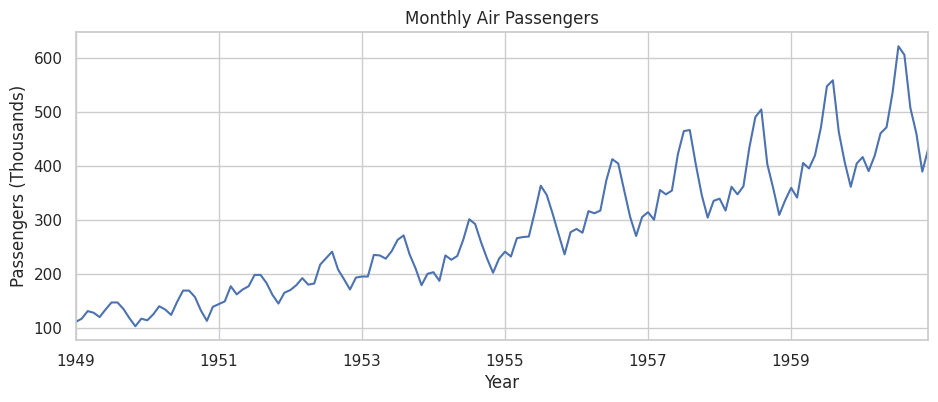

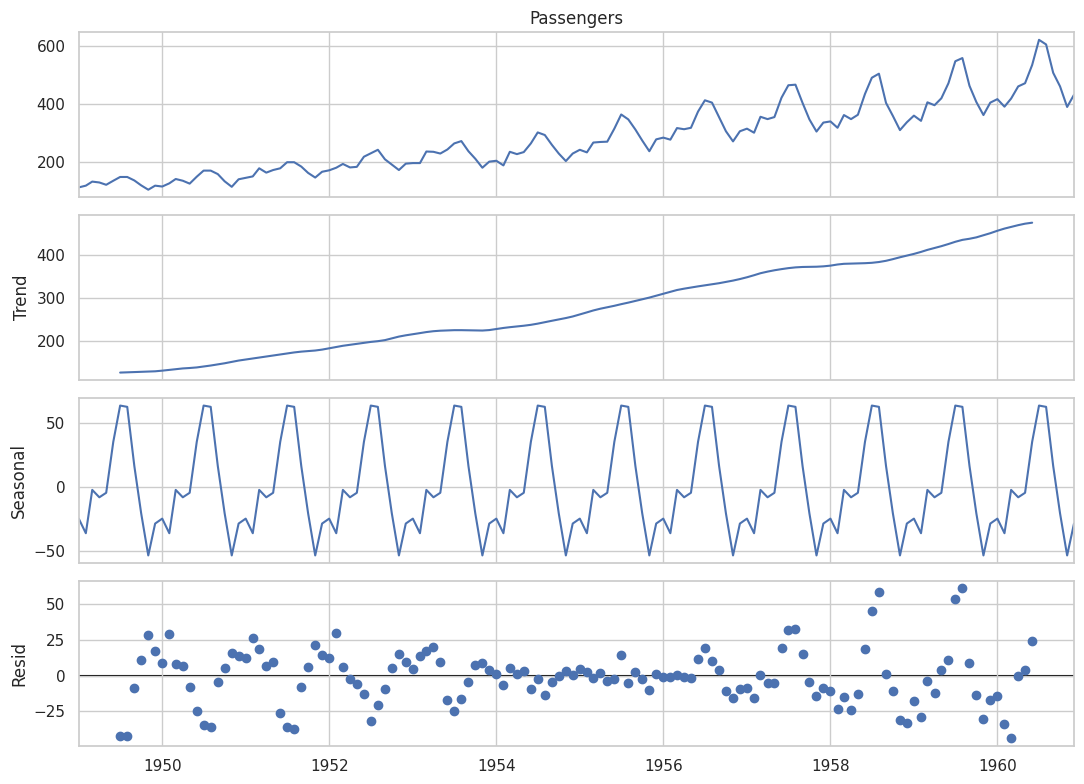

In [16]:
#TIME ANALYSIS

from statsmodels.datasets import get_rdataset
from statsmodels.tsa.seasonal import seasonal_decompose

try:
    passengers = get_rdataset("AirPassengers", "datasets").data
    values = passengers["value"].to_numpy()
except Exception:
    # Use the equivalent AirPassengers series from an installed R dataset
    # or upload the CSV if the online dataset cannot be accessed.
    raise RuntimeError(
        "AirPassengers could not be loaded. "
        "Check the internet connection and run again."
    )

dates = pd.date_range("1949-01-01", periods=len(values), freq="MS")
ts = pd.Series(values, index=dates, name="Passengers")

print("First 5 observations:")
print(ts.head())

print("Last 5 observations:")
print(ts.tail())

print("Start:", ts.index.min())
print("End:", ts.index.max())
print("Frequency: Monthly")
print(ts.describe())

plt.figure(figsize=(11, 4))
ts.plot()
plt.title("Monthly Air Passengers")
plt.xlabel("Year")
plt.ylabel("Passengers (Thousands)")
plt.show()

decomposition = seasonal_decompose(
    ts, model="additive", period=12
)

decomposition.plot()
plt.gcf().set_size_inches(11, 8)
plt.tight_layout()
plt.show()

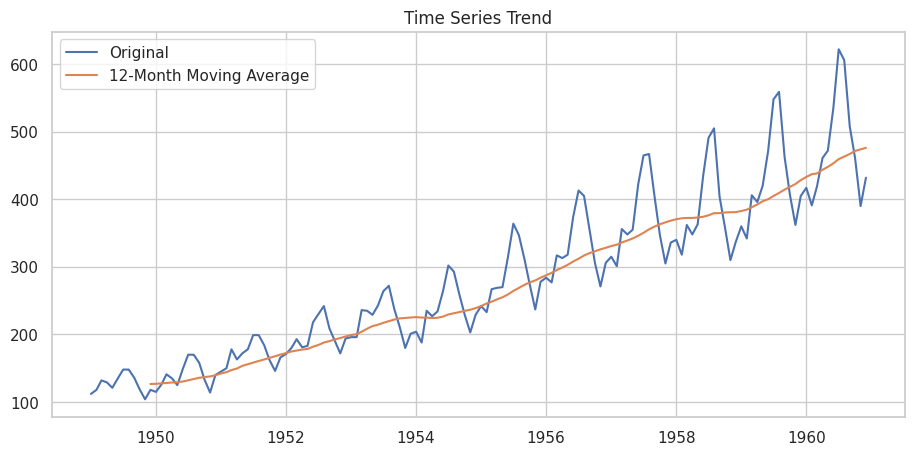

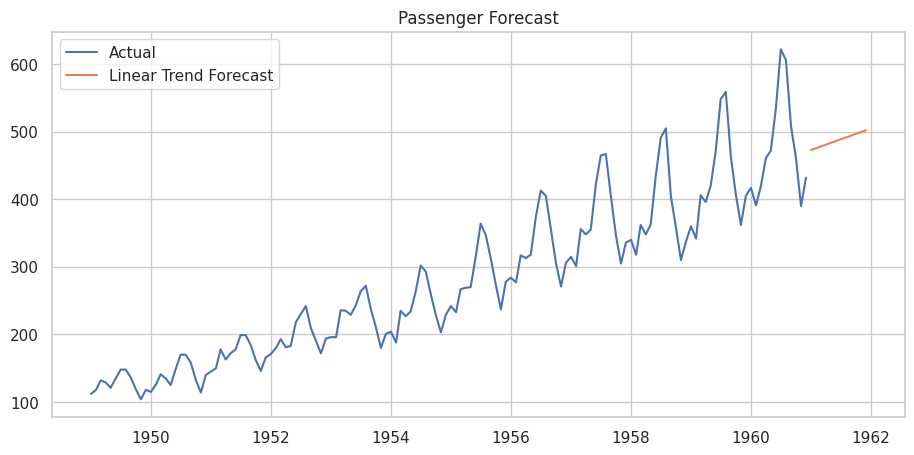

In [17]:
#TS TREND AND FORECAST

rolling_mean = ts.rolling(window=12).mean()

plt.figure(figsize=(11, 5))
plt.plot(ts, label="Original")
plt.plot(rolling_mean, label="12-Month Moving Average")
plt.title("Time Series Trend")
plt.legend()
plt.show()

# Simple linear trend forecast
X = np.arange(len(ts)).reshape(-1, 1)
y = ts.values

trend_model = LinearRegression()
trend_model.fit(X, y)

future_X = np.arange(len(ts), len(ts) + 12).reshape(-1, 1)
forecast = trend_model.predict(future_X)

future_dates = pd.date_range(
    ts.index[-1] + pd.offsets.MonthBegin(1),
    periods=12,
    freq="MS"
)

plt.figure(figsize=(11, 5))
plt.plot(ts.index, ts.values, label="Actual")
plt.plot(future_dates, forecast, label="Linear Trend Forecast")
plt.title("Passenger Forecast")
plt.legend()
plt.show()

Cluster counts:
0    767
1    415
Name: count, dtype: int64
Cluster centers (standardized):


,price,catch,pbeach,ppier,pboat,pcharter,cbeach,cpier,cboat,ccharter,income
0,-0.044944,-0.390694,-0.203470,-0.203470,-0.127296,-0.146939,-0.557567,-0.573730,-0.420846,-0.453623,0.035748
1,0.083066,0.722077,0.376052,0.376052,0.235268,0.271572,1.030491,1.060364,0.777804,0.838382,-0.066069


Silhouette Score: 0.3279191665405502


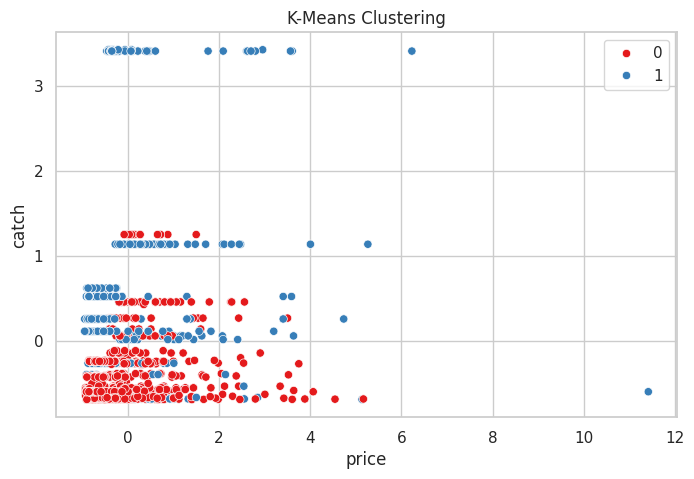

In [18]:
#K-MEANS CLUSTERING

features = data.select_dtypes(include=np.number).drop(
    columns=["rownames"], errors="ignore"
)

features = features.fillna(features.median())
features = features.loc[:, features.std() > 0]

scaler = StandardScaler()
scaled_data = scaler.fit_transform(features)

kmeans = KMeans(n_clusters=2, random_state=123, n_init=10)
clusters = kmeans.fit_predict(scaled_data)

print("Cluster counts:")
print(pd.Series(clusters).value_counts().sort_index())

print("Cluster centers (standardized):")
display(pd.DataFrame(
    kmeans.cluster_centers_,
    columns=features.columns
))

print("Silhouette Score:", silhouette_score(scaled_data, clusters))

plt.figure(figsize=(8, 5))
sns.scatterplot(
    x=scaled_data[:, 0],
    y=scaled_data[:, 1],
    hue=clusters,
    palette="Set1"
)
plt.title("K-Means Clustering")
plt.xlabel(features.columns[0])
plt.ylabel(features.columns[1])
plt.show()

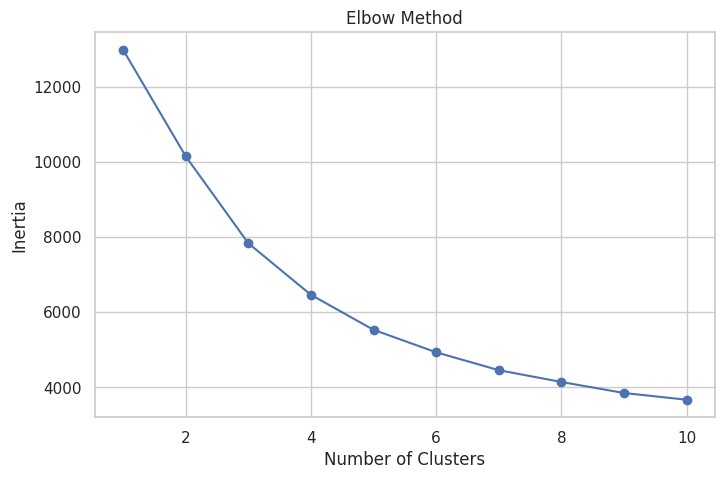

In [19]:
#ELBOW METHOD

inertia = []

for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        random_state=123,
        n_init=10
    )
    model.fit(scaled_data)
    inertia.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.show()

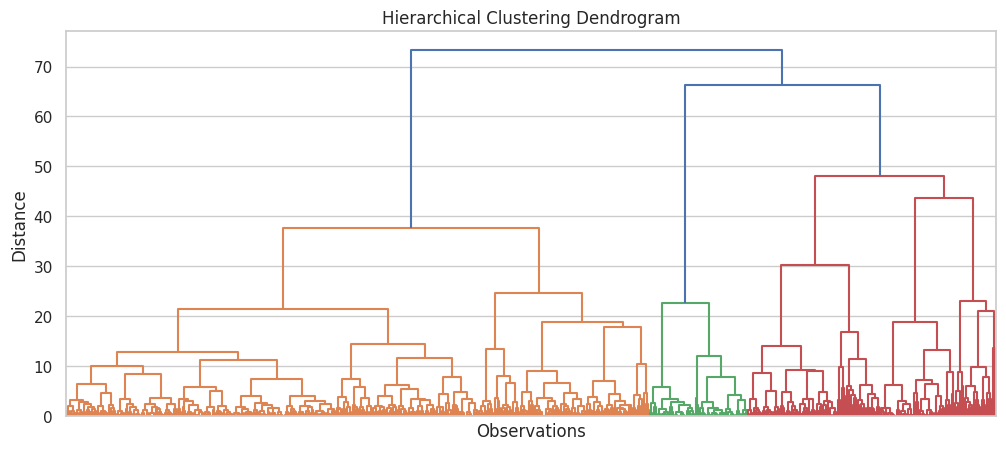

Hierarchical Cluster Counts:
1    741
0    441
Name: count, dtype: int64
Silhouette Score: 0.31839278802493154


In [20]:
#HIERARCHICAL CLUSTERING

from scipy.cluster.hierarchy import linkage, dendrogram

linked = linkage(scaled_data, method="ward")

plt.figure(figsize=(12, 5))
dendrogram(linked, no_labels=True)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Observations")
plt.ylabel("Distance")
plt.show()

hierarchical = AgglomerativeClustering(
    n_clusters=2,
    linkage="ward"
)

hierarchical_labels = hierarchical.fit_predict(scaled_data)

print("Hierarchical Cluster Counts:")
print(pd.Series(hierarchical_labels).value_counts())

print(
    "Silhouette Score:",
    silhouette_score(scaled_data, hierarchical_labels)
)

In [21]:
#PCA ANALYSIS

pca = PCA()
pca_result = pca.fit_transform(scaled_data)

variance = pca.explained_variance_ratio_ * 100

print("Explained variance:")
print(np.round(variance, 2))

print("Cumulative explained variance:")
print(np.round(np.cumsum(variance), 2))

pca_scores = pd.DataFrame(
    pca_result,
    columns=[f"PC{i+1}" for i in range(pca_result.shape[1])]
)

print("First 6 PCA scores:")
display(pca_scores.head(6))

Explained variance:
[3.118e+01 2.567e+01 1.675e+01 1.441e+01 5.710e+00 2.510e+00 1.780e+00
 1.460e+00 5.100e-01 2.000e-02 0.000e+00]
Cumulative explained variance:
[ 31.18  56.85  73.6   88.01  93.72  96.23  98.01  99.47  99.98 100.
 100.  ]
First 6 PCA scores:


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11
0,2.575049,-0.545189,1.646686,-2.106629,-0.468775,0.008024,0.428544,0.037572,-0.353491,0.012128,-2.843763e-16
1,-2.115606,-0.095932,0.323770,-0.106985,-0.724085,0.058725,-0.048721,-0.042247,-0.104103,-0.026240,4.125464e-15
2,0.699667,1.127833,-1.438806,1.759108,0.368534,-0.298256,0.506962,0.031125,0.179530,0.007846,-3.032439e-15
3,-1.569644,-0.444149,0.926745,0.040732,0.080415,-0.557323,-0.177273,-0.380069,-0.014581,0.020565,-2.068441e-15
4,-0.594525,-1.033131,-0.126215,-0.692580,0.123031,-0.168509,-0.047770,-0.217411,-0.060323,0.024584,-2.826700e-15
5,1.373558,0.450827,-1.519462,1.580013,-0.068793,0.398211,0.664929,0.109941,-0.246014,0.042129,-5.565442e-15


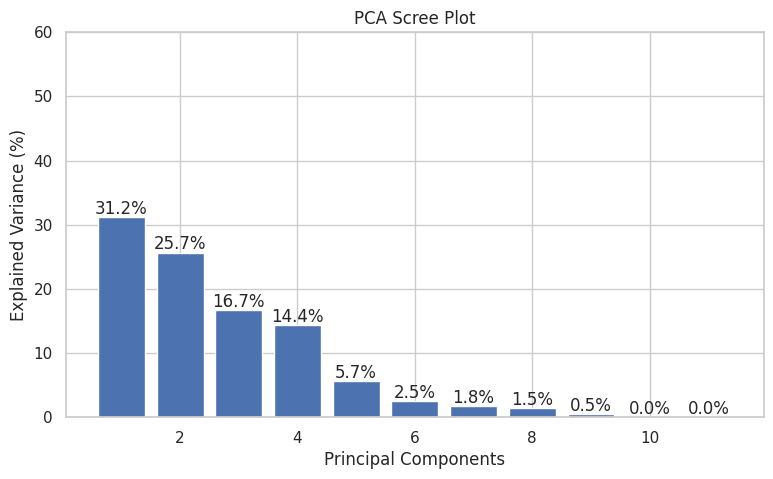

In [22]:
plt.figure(figsize=(9, 5))

plt.bar(
    range(1, len(variance) + 1),
    variance
)

for i, value in enumerate(variance):
    plt.text(i + 1, value + 0.5, f"{value:.1f}%", ha="center")

plt.title("PCA Scree Plot")
plt.xlabel("Principal Components")
plt.ylabel("Explained Variance (%)")
plt.ylim(0, max(60, variance.max() + 5))
plt.show()

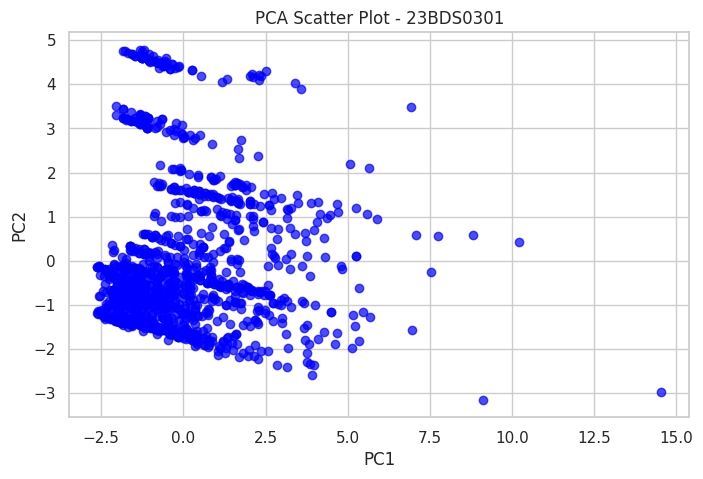

In [23]:
plt.figure(figsize=(8, 5))

plt.scatter(
    pca_scores["PC1"],
    pca_scores["PC2"],
    color="blue",
    alpha=0.7
)

plt.title("PCA Scatter Plot - 23BDS0301")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

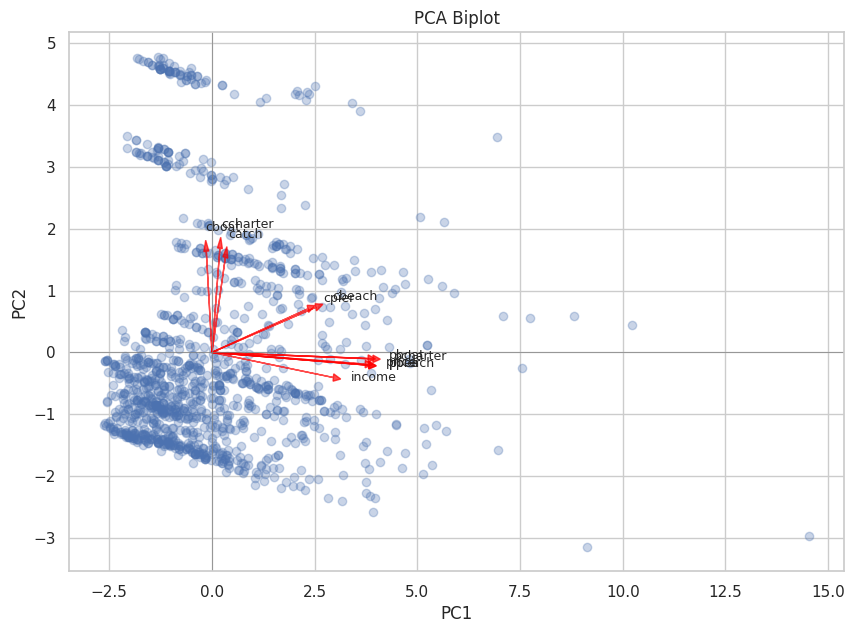

In [24]:
plt.figure(figsize=(10, 7))

plt.scatter(
    pca_result[:, 0],
    pca_result[:, 1],
    alpha=0.3
)

loadings = pca.components_.T

scale_x = np.max(np.abs(pca_result[:, 0])) * 0.7
scale_y = np.max(np.abs(pca_result[:, 1])) * 0.7

for i, col in enumerate(features.columns):
    x = loadings[i, 0] * scale_x
    y = loadings[i, 1] * scale_y

    plt.arrow(
        0, 0, x, y,
        color="red",
        alpha=0.7,
        head_width=0.12,
        length_includes_head=True
    )

    plt.text(x * 1.08, y * 1.08, col, fontsize=9)

plt.title("PCA Biplot")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.axhline(0, color="gray", linewidth=0.5)
plt.axvline(0, color="gray", linewidth=0.5)
plt.grid(True)
plt.show()

In [25]:
#LINEAR REGRESSION

reg_data = data[["price", "income", "catch"]].dropna()

X = reg_data[["price", "income"]]
y = reg_data["catch"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Intercept:", model.intercept_)
print("Coefficients:", model.coef_)

results = pd.DataFrame({
    "Actual Catch": y_test.values,
    "Predicted Catch": y_pred
})

display(results.head(10))

Intercept: 0.423449896235457
Coefficients: [ 1.49101527e-03 -2.68582149e-05]


,Actual Catch,Predicted Catch
0,0.0102,0.400120
1,0.4522,0.398072
2,0.4522,0.379268
3,0.6456,0.389351
4,0.5333,0.379268
5,0.0023,0.382213
6,0.6817,0.371634
7,2.3014,0.395772
8,0.0156,0.411329
9,0.0897,0.623618


Mean Absolute Error: 0.3566
Mean Squared Error: 0.276
Root Mean Squared Error: 0.5253
R2 Score: 0.0381


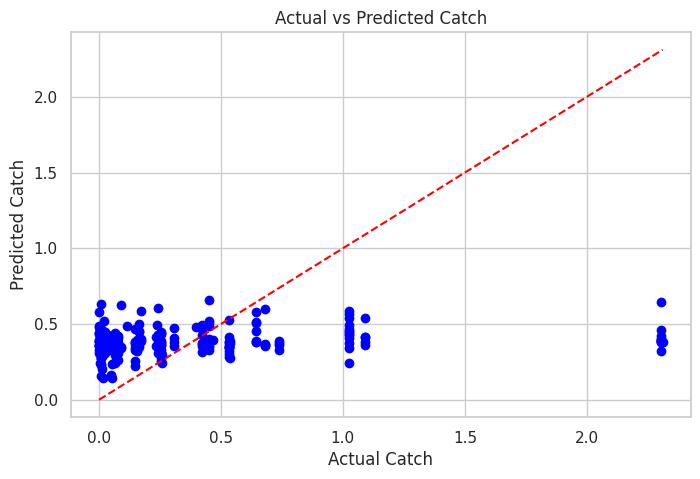

In [26]:
#MODEL EVALUATION

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error:", round(mae, 4))
print("Mean Squared Error:", round(mse, 4))
print("Root Mean Squared Error:", round(rmse, 4))
print("R2 Score:", round(r2, 4))

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, color="blue")

plt.plot(
    [min(y_test.min(), y_pred.min()),
     max(y_test.max(), y_pred.max())],
    [min(y_test.min(), y_pred.min()),
     max(y_test.max(), y_pred.max())],
    color="red",
    linestyle="--"
)

plt.xlabel("Actual Catch")
plt.ylabel("Predicted Catch")
plt.title("Actual vs Predicted Catch")
plt.show()

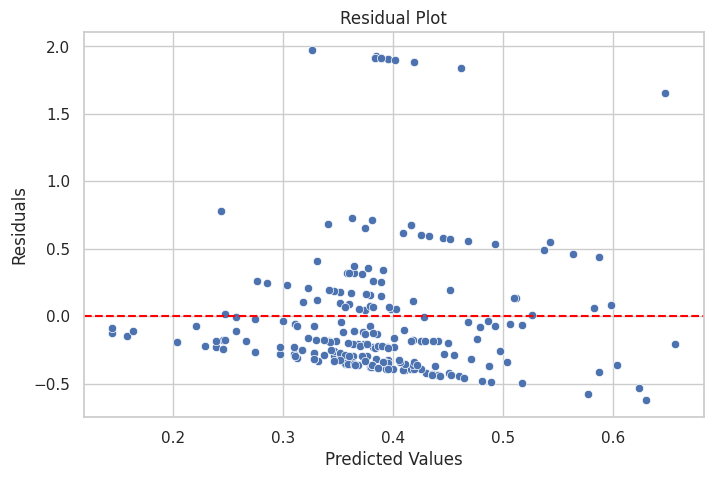

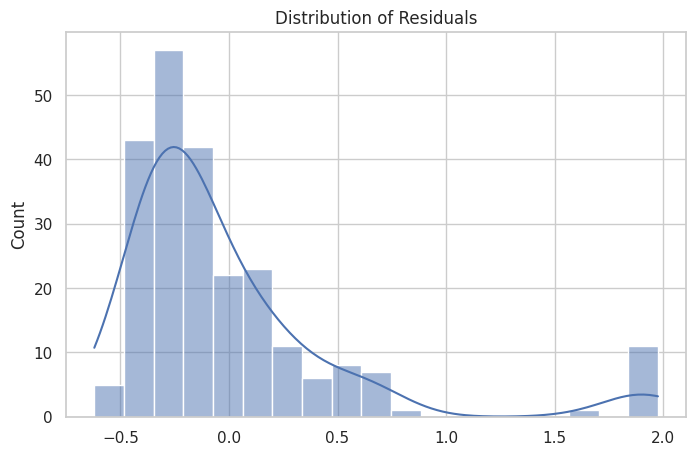

In [27]:
residuals = y_test.values - y_pred

plt.figure(figsize=(8, 5))
sns.scatterplot(x=y_pred, y=residuals)
plt.axhline(0, color="red", linestyle="--")
plt.title("Residual Plot")
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.show()

plt.figure(figsize=(8, 5))
sns.histplot(residuals, kde=True)
plt.title("Distribution of Residuals")
plt.show()

Learned Q Table:
[[ 3.11  4.58]
 [ 3.12  6.2 ]
 [ 4.57  8.  ]
 [ 6.19 10.  ]
 [ 0.    0.  ]]
Best action for each state:
[1 1 1 1 0]


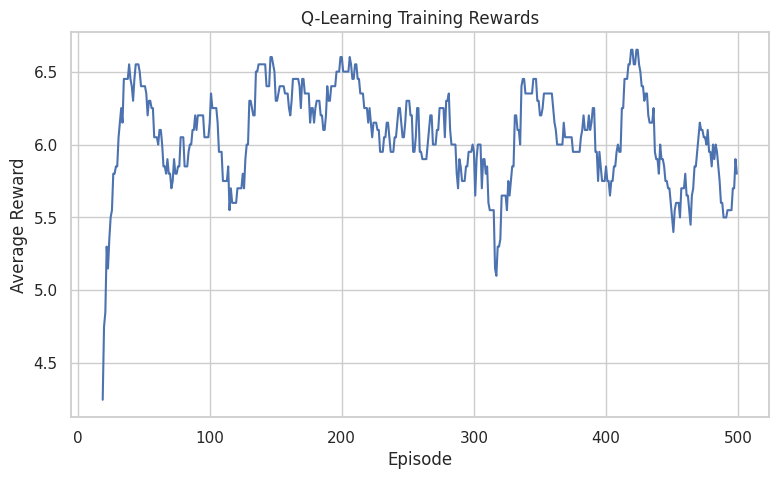

In [29]:
#REINFORCEMENT LEARNINNG
np.random.seed(42)

states = 5
actions = 2

Q = np.zeros((states, actions))

alpha = 0.1
gamma = 0.9
epsilon = 0.2
episodes = 500

rewards = []

for episode in range(episodes):
    state = 0
    total_reward = 0

    for step in range(20):

        if np.random.rand() < epsilon:
            action = np.random.randint(actions)
        else:
            action = np.argmax(Q[state])

        if action == 0:
            next_state = max(0, state - 1)
        else:
            next_state = min(states - 1, state + 1)

        reward = 10 if next_state == states - 1 else -1
        done = next_state == states - 1

        future_reward = 0 if done else np.max(Q[next_state])

        Q[state, action] = Q[state, action] + alpha * (
            reward + gamma * future_reward - Q[state, action]
        )

        total_reward += reward
        state = next_state

        if done:
            break

    rewards.append(total_reward)

print("Learned Q Table:")
print(np.round(Q, 2))

print("Best action for each state:")
print(np.argmax(Q, axis=1))

plt.figure(figsize=(9, 5))
plt.plot(pd.Series(rewards).rolling(20).mean())
plt.title("Q-Learning Training Rewards")
plt.xlabel("Episode")
plt.ylabel("Average Reward")
plt.show()

In [31]:
#SUMMARY
print("=" * 50)
print("EXPLORATORY DATA ANALYSIS OF FISHING DATA")
print("=" * 50)

print("\nDataset Information")
print("Total Records:", len(data))
print("Total Features:", data.shape[1])
print("Missing Values:", data.isnull().sum().sum())

print("\nStatistical Analysis")
print("Average Price:", round(data["price"].mean(), 2))
print("Average Income:", round(data["income"].mean(), 2))
print("Average Catch:", round(data["catch"].mean(), 2))

print("\nClustering")
print("K-Means Clusters:", len(np.unique(clusters)))
print("Hierarchical Clusters:", len(np.unique(hierarchical_labels)))

print("\nDimensionality Reduction")
print("PC1 Variance:", round(variance[0], 2), "%")
print("PC2 Variance:", round(variance[1], 2), "%")

print("\nRegression Performance")
print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))
print("R2 Score:", round(r2, 4))



EXPLORATORY DATA ANALYSIS OF FISHING DATA

Dataset Information
Total Records: 1182
Total Features: 13
Missing Values: 0

Statistical Analysis
Average Price: 52.08
Average Income: 4099.34
Average Catch: 0.39

Clustering
K-Means Clusters: 2
Hierarchical Clusters: 2

Dimensionality Reduction
PC1 Variance: 31.18 %
PC2 Variance: 25.67 %

Regression Performance
MAE: 0.3566
RMSE: 0.5253
R2 Score: 0.0381
